In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
df = pd.read_csv("data_MLR.csv")

In [3]:
print("Shape:", df.shape)

Shape: (1000, 12)


In [4]:
print(df.isnull().sum())

y      0
x1     0
x2     0
x3     0
x4     0
x5     0
x6     0
x7     0
x8     0
x9     0
x10    0
x11    0
dtype: int64


In [5]:
X = df.drop(columns=["y"])

In [6]:
y = df["y"]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20, random_state=42)

In [8]:
scaler = StandardScaler()

In [9]:
X_train_s = pd.DataFrame( scaler.fit_transform(X_train),columns=X_train.columns,index=X_train.index)

In [10]:
X_test_s = pd.DataFrame( scaler.transform(X_test),columns=X_test.columns,index=X_test.index)

In [11]:
print("Training shape:", X_train_s.shape)
print("Testing shape:", X_test_s.shape)

Training shape: (800, 11)
Testing shape: (200, 11)


In this dataset there are 1000 obv 11 predictors and one continous response and yaa no missing value too and i splitted the data for training and testing 

### Step 2—Fit the full MLR model and record Adjusted R² Ftest pvalue and coef pvalues.

In [12]:
X_train_sm = sm.add_constant(X_train_s)

In [13]:
model = sm.OLS(y_train, X_train_sm).fit()

In [14]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.204
Model:                            OLS   Adj. R-squared:                  0.193
Method:                 Least Squares   F-statistic:                     18.40
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           5.86e-33
Time:                        15:01:50   Log-Likelihood:                -4310.9
No. Observations:                 800   AIC:                             8646.
Df Residuals:                     788   BIC:                             8702.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -41.0891      1.887    -21.776      0.0

In [15]:
print("Adjusted R²:", model.rsquared_adj)
print("Overall F-test p-value:", model.f_pvalue)

Adjusted R²: 0.193279035161521
Overall F-test p-value: 5.8596811975076285e-33


In [16]:
coef_table = pd.DataFrame({"Coefficient": model.params,"p-value": model.pvalues})

In [ ]:
coef_table

,Coefficient,p-value
const,-41.089086,1.126698e-82
x1,-231.156284,5.347632e-01
x2,-236.839795,5.369810e-01
x3,13.098546,1.903519e-04
x4,353.424622,5.179061e-01
x5,5.923232,1.865426e-03
x6,6.342326,8.975670e-04
x7,-3.219913,9.005543e-02
x8,2.244991,5.120773e-01
x9,48.745980,1.432101e-01


In [18]:
features = list(X.columns)

The full model is statistically significant overall because the F-test p-value is far below 0.05. The individual p-values show that several predictors are not significant when all 11 predictors are included. However, feature removal is postponed until after the required VIF and influence diagnostics.

In [19]:
vif_log = []

In [20]:
while True:

    X_vif = sm.add_constant(X_train_s[features])

    vif = []

    for i in range(1, X_vif.shape[1]):
        vif.append(variance_inflation_factor(X_vif.values, i))

    vif_table = pd.DataFrame({
        "Feature": features,
        "VIF": vif
    })

    vif_table = vif_table.sort_values("VIF", ascending=False)

    max_feature = vif_table.iloc[0]["Feature"]
    max_vif = vif_table.iloc[0]["VIF"]

    if max_vif <= 10:
        break

    features.remove(max_feature)

    model = sm.OLS(
        y_train,
        sm.add_constant(X_train_s[features])
    ).fit()

    vif_log.append({
        "Dropped Feature": max_feature,
        "VIF": max_vif,
        "Adjusted R²": model.rsquared_adj
    })


In [21]:
print("VIF Refinement Log:")
display(pd.DataFrame(vif_log))

VIF Refinement Log:


,Dropped Feature,VIF,Adjusted R²
0,x4,83844.209474,0.193874
1,x11,1436.833433,0.192772


In [22]:
print("Final VIF:")
display(vif_table)

Final VIF:


,Feature,VIF
0,x1,3.424336
2,x3,3.422518
6,x8,3.283759
8,x10,3.266725
7,x9,1.018322
4,x6,1.015626
5,x7,1.010546
1,x2,1.007536
3,x5,1.004555


In [23]:
X_vif = sm.add_constant(X_train_s[features])
vif = []
for i in range(1, X_vif.shape[1]):
    vif.append(variance_inflation_factor(X_vif.values, i))
final_vif = pd.DataFrame({
    "Feature": features,
    "VIF": vif
})
display(final_vif)

,Feature,VIF
0,x1,3.424336
1,x2,1.007536
2,x3,3.422518
3,x5,1.004555
4,x6,1.015626
5,x7,1.010546
6,x8,3.283759
7,x9,1.018322
8,x10,3.266725


We checked the VIF values and removed features with VIF greater than 10
First i removed x4 because its VIF was very high (83844.21)
After recalculating VIF i removed x11 because its VIF was 1436.83
After removing these two features all remaining VIF values were below 10
and sooooo we kept x1, x2, x3, x5, x6, x7, x8, x9, and x10

In [24]:
model = sm.OLS( y_train,sm.add_constant(X_train_s[features])).fit()

In [25]:
influence = model.get_influence()

In [26]:
cooks_d = influence.cooks_distance[0]

In [27]:
dffits = influence.dffits[0]

In [28]:
n = len(y_train)
p = len(features) + 1

In [29]:
cook_threshold = 4 / n
dffits_threshold = 2 * np.sqrt(p / n)

In [30]:
print("Cook's Distance threshold:", cook_threshold)
print("DFFITS threshold:", dffits_threshold)

Cook's Distance threshold: 0.005
DFFITS threshold: 0.22360679774997896


In [31]:
cook_flagged = y_train.index[cooks_d > cook_threshold]
dffits_flagged = y_train.index[abs(dffits) > dffits_threshold]

In [32]:
print("Cook's Distance flagged:", len(cook_flagged))
print("DFFITS flagged:", len(dffits_flagged))

Cook's Distance flagged: 58
DFFITS flagged: 58


In [33]:
influential = sorted(set(cook_flagged) | set(dffits_flagged))

In [34]:
print("Total influential observations:", len(influential))
print("Indices:", influential)

Total influential observations: 58
Indices: [5, 13, 18, 28, 64, 68, 80, 132, 135, 164, 169, 182, 193, 206, 241, 245, 250, 251, 264, 269, 297, 305, 323, 337, 339, 368, 386, 413, 415, 446, 458, 512, 530, 532, 556, 592, 594, 615, 667, 674, 681, 700, 733, 752, 762, 780, 793, 804, 813, 834, 838, 839, 848, 852, 934, 955, 963, 996]


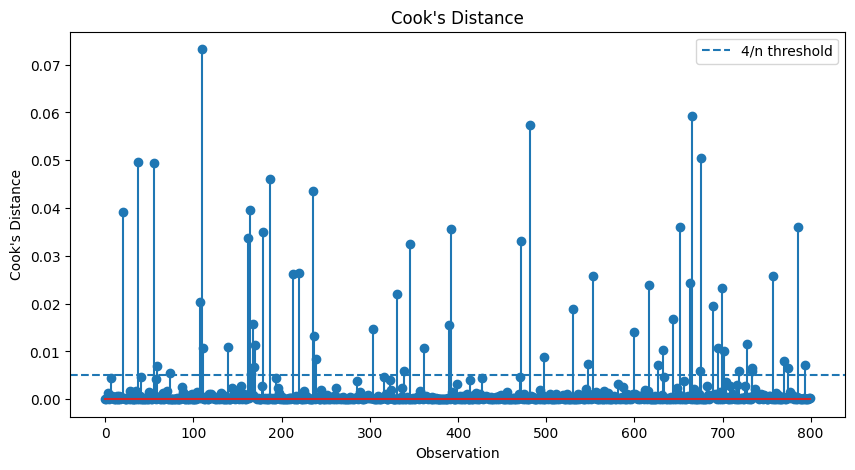

In [35]:
plt.figure(figsize=(10, 5))

plt.stem(range(len(cooks_d)), cooks_d)

plt.axhline(
    cook_threshold,
    linestyle="--",
    label="4/n threshold"
)

plt.title("Cook's Distance")
plt.xlabel("Observation")
plt.ylabel("Cook's Distance")
plt.legend()

plt.show()

In [36]:
model_without = sm.OLS(
    y_train.drop(index=influential),
    sm.add_constant(
        X_train_s.drop(index=influential)[features]
    )
).fit()

print("Adjusted R² before removal:", model.rsquared_adj)
print("Adjusted R² after removal:", model_without.rsquared_adj)

Adjusted R² before removal: 0.192771848302687
Adjusted R² after removal: 0.8367447264188198


I checked Cook's Distance and DFFITS to find influential observations. The observations crossing the given thresholds were considered influential. We removed these observations and fitted the model again. The Adjusted R² increased from 0.19277 to 0.83674, so removing these observations improved the model. Therefore, we used the cleaned training data for the next step.

In [37]:
features = list(features)

In [38]:
step_log = []

In [39]:
while True:

    model = sm.OLS(y_train.drop(index=influential),sm.add_constant( X_train_s.drop(index=influential)[features] )).fit()
    pvalues = model.pvalues.drop("const")
    max_feature = pvalues.idxmax()
    max_pvalue = pvalues.max()
    if max_pvalue <= 0.05:
        break
    features.remove(max_feature)
    new_model = sm.OLS( y_train.drop(index=influential),   sm.add_constant(        X_train_s.drop(index=influential)[features]  )  ).fit()
    step_log.append({
        "Dropped Feature": max_feature,
        "p-value": max_pvalue,
        "Adjusted R²": new_model.rsquared_adj
    })


In [40]:
print("Stepwise Refinement:")
display(pd.DataFrame(step_log))

Stepwise Refinement:


,Dropped Feature,p-value,Adjusted R²
0,x10,0.652885,0.836922
1,x9,0.378250,0.836972


In [41]:

print("Final Features:")
print(features)

Final Features:
['x1', 'x2', 'x3', 'x5', 'x6', 'x7', 'x8']


I checked the p-values of all remaining features. x10 had the highest p-value, so we removed it. After refitting the model, x9 had the highest p-value, so we removed it. After this, all remaining features had p-values below 0.05, so we stopped the feature removal process. The final features are x1, x2, x3, x5, x6, x7, and x8.

In [42]:
final_model = sm.OLS( y_train.drop(index=influential), sm.add_constant(X_train_s.drop(index=influential)[features] )).fit()
residuals = final_model.resid
fitted = final_model.fittedvalues

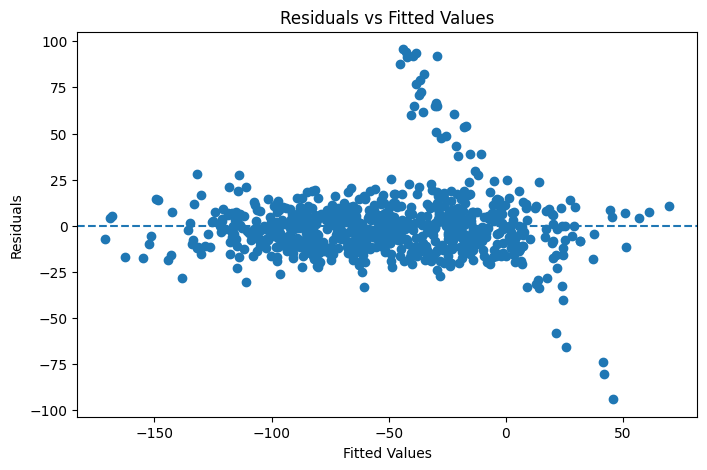

In [43]:
plt.figure(figsize=(8, 5))

plt.scatter(fitted, residuals)

plt.axhline(0, linestyle="--")

plt.title("Residuals vs Fitted Values")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")

plt.show()

<Figure size 800x500 with 0 Axes>

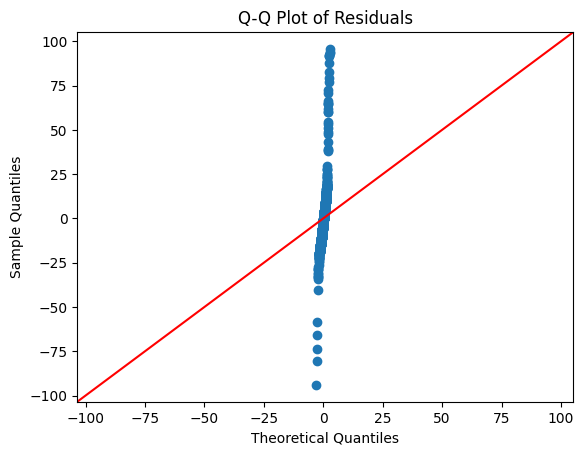

In [44]:
plt.figure(figsize=(8, 5))

sm.qqplot(residuals, line="45")

plt.title("Q-Q Plot of Residuals")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")

plt.show()

I used the Residuals vs Fitted plot to check linearity and equal variance. We used the Q-Q plot to check normality of residuals. The plots are used to see whether the assumptions of the linear regression model are reasonably satisfied.

In [45]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [46]:
y_pred = final_model.predict(sm.add_constant(X_test_s[features]))

In [47]:
mae = mean_absolute_error(y_test, y_pred)

In [48]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

In [ ]:
r2 = r2_score(y_test, y_pred)

In [50]:
print("Training Adjusted R²:", final_model.rsquared_adj)
print("Test MAE:", mae)
print("Test RMSE:", rmse)
print("Test R²:", r2)

Training Adjusted R²: 0.8369718326941689
Test MAE: 25.707114311353827
Test RMSE: 56.67807340320827
Test R²: 0.14125596584334998


Final features: x1, x2, x3, x5, x6, x7, x8
x4 and x11 were removed because their VIF was greater than 10.
Influential observations were removed using Cook's Distance and DFFITS.
x10 and x9 were removed because their p-values were greater than 0.05.
Training Adjusted R² = 0.837
Test MAE = 25.71
Test RMSE = 56.68
Test R² = 0.141
The model performs better on training data than on test data, so its performance on new data is limited.